In [1]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_chroma import Chroma
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent
from langchain.tools import tool

/var/folders/lj/f_7_9gm954v3m19vl9qwk8_c0000gn/T/ipykernel_49745/1951303594.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
from dotenv import load_dotenv
load_dotenv()

True

In [3]:
loader = PyPDFLoader("data/daily_food_guide.pdf")
pages = loader.load()
print(len(pages))

29


In [4]:
doc = pages[0]
print(type(doc))
print(doc.metadata)

<class 'langchain_core.documents.base.Document'>
{'producer': 'Adobe Acrobat Pro DC 17.9.20044', 'creator': 'Adobe Acrobat Pro DC 17.9.20044', 'creationdate': '2018-10-18T09:21:42+08:00', 'moddate': '2018-10-18T09:21:42+08:00', 'title': '', 'source': 'data/daily_food_guide.pdf', 'total_pages': 29, 'page': 0, 'page_label': '1'}


In [5]:
for d in pages:
    page_no = d.metadata["page_label"]
    text = d.page_content
    print(f"第 {page_no:>2} 頁：{len(text):>5} 字　{text[:30]!r}")

第  1 頁：   87 字　'局\n衛生福利部\n國民健康署\n守護健康\n˕Ꮠ ᄿѓ\n全榖雜糧類'
第  2 頁：  169 字　'ҏ\neॹ˶༶ਗeʔ\u0e85භৢ\n\u05f5 \x17\x12\x11\x13\nϋ \x14 ̺ \x13\x11\x12\x17'
第  3 頁：   79 字　'每日飲食指南\n前言 2\n如何使用我的每日飲食指南 6\n全穀雜'
第  4 頁：  538 字　'前\n言\n均衡飲食的意義\n每日由飲食中獲得足夠量的身體所需每種'
第  5 頁：  481 字　'規劃原則\n本版每日飲食指南三大營養素占總熱量比例範圍為 ：\n'
第  6 頁：  347 字　'前\n言\n加上原本的「蔬菜類」、「水果類」，本版每日飲食指南\n'
第  7 頁：  684 字　'前\n言\n變更概述\n檢視舊版每日飲食指南適用性之分析結果，發現'
第  8 頁： 1096 字　'用\n使\n何\n如\n我\n的\n每\n日\n飲\n食\n指\n南\n1. 找到自'
第  9 頁：  460 字　'2. 看看自己每天的生活活動強度\n \n生活活動強度\n低\n生活'
第 10 頁：  542 字　'用\n使\n何\n如\n我\n的\n每\n日\n飲\n食\n指\n南\n查出自己的熱'
第 11 頁：  687 字　'依熱量需求，查出自己的六大類飲食建議份數\n1200\n大卡\n1'
第 12 頁：  724 字　'用\n使\n何\n如\n我\n的\n每\n日\n飲\n食\n指\n南\n六大類食物代'
第 13 頁：  429 字　'六大類食物代換份量\n蔬菜類 1份(1 份為可食部分生重約 1'
第 14 頁：  549 字　'類\n糧\n雜\n穀\n全\n全穀雜糧類食物的營養成分\n及功能\n全穀雜'
第 15 頁：  763 字　'食」 ， 於飲食中食用量最多。 惟此類食物若經加工精製 （如'
第 16 頁：  462 字　'類\n肉\n蛋\n魚\n豆\n豆魚蛋肉類食物的營養成分\n及功能\n豆魚蛋'
第 17 頁：  558 字　'量大於 75 毫克之豆製品稱為高鈣豆製品。例如：大豆干、傳\n'
第 18 頁：  486 字　'生素 B1、B2 和鐵、磷等礦物質，因\n此蛋可說是既便宜又營'
第 19 頁：  562 字　'梅

In [6]:
print(repr(pages[10].page_content))

'依熱量需求，查出自己的六大類飲食建議份數\n1200\n大卡\n1500\n大卡\n1800\n大卡\n2000\n大卡\n2200\n大卡\n2500\n大卡\n2700\n大卡\n全穀雜糧類 ( 碗 ) 1.5 2.5 3 3 3.5 4 4\n全穀雜糧類 (未\n精製 *)( 碗 )\n1 1 1 1 1.5 1.5 1.5\n全穀雜糧類(其\n他* ) (碗)\n0.5 1.5 2 2 2 2.5 2.5\n豆魚蛋肉類 ( 份 ) 3\n(註1 )\n4\n(註2 )\n5 6 6 7 8\n乳 品 類(杯) 1.5 1.5 1.5 1.5 1.5 1.5 2\n蔬 菜 類(份) 3\n(註3 )\n3 3 4 4 5 5\n水 果 類(份) 2 2 2 3 3.5 4 4\n油脂與堅果 \n種 子 類(份)\n4 4 5 6 6 7 8\n油脂類 ( 茶匙 ) 3 3 4 5 5 6 7\n堅果種子 ( 份 ) 1\n(註4 )\n1 1 1 1 1 1\n查出自己的熱量需求 依熱量需求，查出自己的六大類飲食建議份數\n表四 依熱量需求的六大類飲食建議份數\n*「未精製」主食品，如糙米飯、全麥食品、燕麥、玉米、甘薯等，請依據「六大類食物簡介」。\n  「其他」指白米飯、白麵條、白麵包、饅頭等。以「未精製」取代「其他」，更佳。\n（註 1）高鈣豆製品至少占 1/3 以確保鈣質充裕；（註 2）攝取 1500 大卡的青少年，高鈣豆製品  \n   至少占 1/3 以確保鈣質充裕；（註 3）深色蔬菜比例至少占 1/2 以確保鈣質充裕（註 4）選擇高\n   維生素 E 堅果種子的種類，包括花生仁、杏仁片、杏仁果、葵瓜子、松子仁。\n4.\n9'


共 29 頁


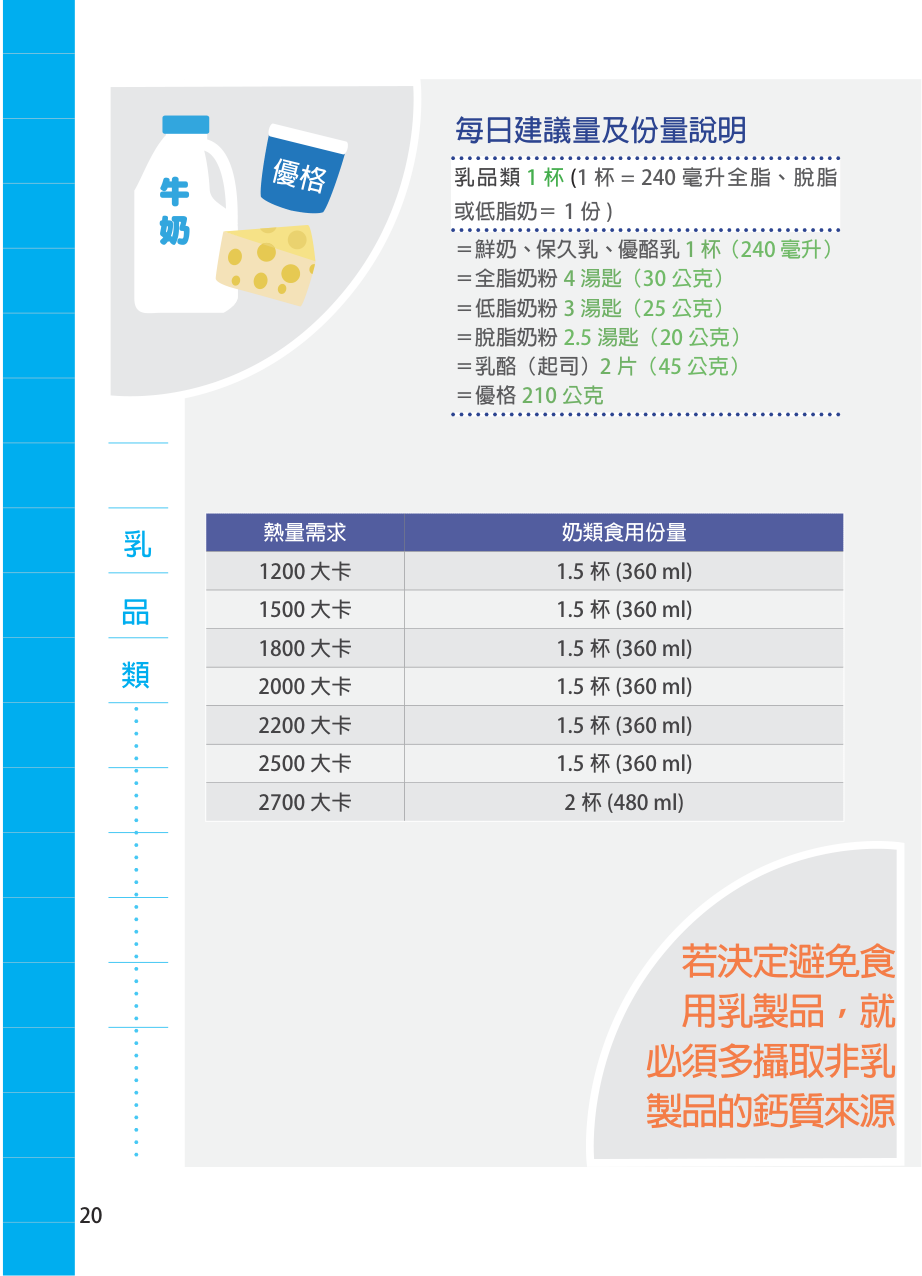

In [7]:
import pymupdf
from IPython.display import Image, display

pdf = pymupdf.open("data/daily_food_guide.pdf")
print(f"共 {len(pdf)} 頁")

png = pdf[21].get_pixmap(dpi=150).tobytes("png")   # 第 22 頁（index 21）
display(Image(png, width=400))

In [8]:
from langchain.chat_models import init_chat_model
from langchain_core.messages import HumanMessage
import base64

vision_llm = init_chat_model("anthropic:claude-sonnet-5-5")

PAGE_PROMPT = """這是衛福部國民健康署《每日飲食指南手冊》的其中一頁。請把這一頁的內容完整轉成 Markdown：

1. 如果頁面側邊有直排的分類標籤（例如「全穀雜糧類」、「乳品類」），請把它當成最上方的一級標題 #。
2. 頁面中的標題用 ## 或 ###。
3. 表格轉成 Markdown 表格，保留表格標題、所有欄位名稱和數字。數字必須完全照原文，不可以更改或推算。
4. 表格的附註、註解都要保留。
5. 圖片上如果有文字說明（例如份量示意圖上的說明），請轉成文字；純裝飾的圖片不用描述。
6. 頁碼不要輸出。
7. 只輸出 Markdown 內容，不要加任何說明或開場白。"""

In [9]:
def page_to_markdown(i: int) -> str:
    png = pdf[i].get_pixmap(dpi=150).tobytes("png")
    b64 = base64.b64encode(png).decode()
    msg = HumanMessage(content=[
        {"type": "text", "text": PAGE_PROMPT},
        {"type": "image", "base64": b64, "mime_type": "image/png"},
    ])
    return vision_llm.invoke([msg]).text

In [10]:
from pathlib import Path

out_dir = Path("data/pages")
out_dir.mkdir(exist_ok=True)

for i in range(len(pdf)):
    path = out_dir / f"page_{i + 1:02d}.md"
    if path.exists():
        print(f"第 {i + 1:>2} 頁：已存在，跳過")
        continue
    md = page_to_markdown(i)
    path.write_text(md, encoding="utf-8")
    print(f"第 {i + 1:>2} 頁：完成，{len(md)} 字")

第  1 頁：已存在，跳過
第  2 頁：已存在，跳過
第  3 頁：已存在，跳過
第  4 頁：已存在，跳過
第  5 頁：已存在，跳過
第  6 頁：已存在，跳過
第  7 頁：已存在，跳過
第  8 頁：已存在，跳過
第  9 頁：已存在，跳過
第 10 頁：已存在，跳過
第 11 頁：已存在，跳過
第 12 頁：已存在，跳過
第 13 頁：已存在，跳過
第 14 頁：已存在，跳過
第 15 頁：已存在，跳過
第 16 頁：已存在，跳過
第 17 頁：已存在，跳過
第 18 頁：已存在，跳過
第 19 頁：已存在，跳過
第 20 頁：已存在，跳過
第 21 頁：已存在，跳過
第 22 頁：已存在，跳過
第 23 頁：已存在，跳過
第 24 頁：已存在，跳過
第 25 頁：已存在，跳過
第 26 頁：已存在，跳過
第 27 頁：已存在，跳過
第 28 頁：已存在，跳過
第 29 頁：已存在，跳過


In [11]:
for n in [11,12,22]:
    print(f"\n ==== {n} ====")
    print((out_dir / f"page_{n:02d}.md").read_text(encoding="utf-8"))


 ==== 11 ====
## 4. 依熱量需求，查出自己的六大類飲食建議份數

### 表四 依熱量需求的六大類飲食建議份數

**依熱量需求，查出自己的六大類飲食建議份數**

| | 1200 大卡 | 1500 大卡 | 1800 大卡 | 2000 大卡 | 2200 大卡 | 2500 大卡 | 2700 大卡 |
|---|---|---|---|---|---|---|---|
| 全穀雜糧類 (碗) | 1.5 | 2.5 | 3 | 3 | 3.5 | 4 | 4 |
| 　全穀雜糧類 (未精製 *)(碗) | 1 | 1 | 1 | 1 | 1.5 | 1.5 | 1.5 |
| 　全穀雜糧類 (其他 *)(碗) | 0.5 | 1.5 | 2 | 2 | 2 | 2.5 | 2.5 |
| 豆魚蛋肉類 (份) | 3 (註 1) | 4 (註 2) | 5 | 6 | 6 | 7 | 8 |
| 乳品類 (杯) | 1.5 | 1.5 | 1.5 | 1.5 | 1.5 | 1.5 | 2 |
| 蔬菜類 (份) | 3 (註 3) | 3 | 3 | 4 | 4 | 5 | 5 |
| 水果類 (份) | 2 | 2 | 2 | 3 | 3.5 | 4 | 4 |
| 油脂與堅果種子類 (份) | 4 | 4 | 5 | 6 | 6 | 7 | 8 |
| 　油脂類 (茶匙) | 3 | 3 | 4 | 5 | 5 | 6 | 7 |
| 　堅果種子 (份) | 1 (註 4) | 1 | 1 | 1 | 1 | 1 | 1 |

\*「未精製」主食品，如糙米飯、全麥食品、燕麥、玉米、甘薯等，請依據「六大類食物簡介」。「其他」指白米飯、白麵條、白麵包、饅頭等。以「未精製」取代「其他」，更佳。

（註 1）高鈣豆製品至少占 1/3 以確保鈣質充裕；（註 2）攝取 1500 大卡的青少年，高鈣豆製品至少占 1/3 以確保鈣質充裕；（註 3）深色蔬菜比例至少占 1/2 以確保鈣質充裕（註 4）選擇高維生素 E 堅果種子的種類，包括花生仁、杏仁片、杏仁果、葵瓜子、松子仁。

 ==== 12 ====
# 如何使用我的每日飲食指南

## 六大類食物代換份量

### 全穀雜糧類 1 碗（碗為一般家用飯碗、重量為可食重量）

- = 糙米飯 1

In [12]:
from pathlib import Path
from langchain_community.document_loaders import TextLoader

SKIP_PAGES = {1,3,29}
page_docs = []
for path in sorted(Path("data/pages").glob("page_*.md")):
    page_no = int(path.stem.split("_")[1])
    if page_no in SKIP_PAGES:
        continue
    doc = TextLoader(str(path), encoding="utf-8").load()[0]
    doc.metadata["page"] = page_no
    page_docs.append(doc)

print(f"Total page: {len(page_docs)} ")

Total page: 26 


In [13]:
from langchain_text_splitters import MarkdownHeaderTextSplitter

splitter = MarkdownHeaderTextSplitter(
    headers_to_split_on=[
        ("#", "category"),       # # 一級標題 → 存進 metadata["category"]
        ("##", "section"),       # ## 二級標題 → metadata["section"]
        ("###", "subsection"),   # ### 三級標題 → metadata["subsection"]
    ],
    strip_headers=False,         # 切完後，標題文字仍保留在內容裡
)

test = splitter.split_text(page_docs[9].page_content)   # 挑一頁來試
for c in test:
    print(c.metadata)
    print(c.page_content[:80])
    print("---")

{'category': '如何使用我的每日飲食指南', 'section': '六大類食物代換份量', 'subsection': '全穀雜糧類 1 碗（碗為一般家用飯碗、重量為可食重量）'}
# 如何使用我的每日飲食指南  
## 六大類食物代換份量  
### 全穀雜糧類 1 碗（碗為一般家用飯碗、重量為可食重量）  
- = 糙米飯 1 碗 或 
---
{'category': '如何使用我的每日飲食指南', 'section': '六大類食物代換份量', 'subsection': '豆魚蛋肉類 1 份（重量為可食部分生重）'}
### 豆魚蛋肉類 1 份（重量為可食部分生重）  
- = 黃豆 (20 公克) 或 毛豆 (50 公克) 或 黑豆 (25 公克)
- = 無糖豆漿 1 杯
---
{'category': '如何使用我的每日飲食指南', 'section': '六大類食物代換份量', 'subsection': '乳品類 1 杯（1 杯 = 240 毫升全脂、脫脂或低脂奶 = 1 份）'}
### 乳品類 1 杯（1 杯 = 240 毫升全脂、脫脂或低脂奶 = 1 份）  
- = 鮮奶、保久乳、優酪乳 1 杯（240 毫升）
- = 全脂奶粉 4
---


In [14]:
chunks = []
current_category = ""

for page in page_docs:
    for j, c in enumerate(splitter.split_text(page.page_content)):

        # ★ 新增：這一頁的第一塊沒有 ## 或 ### 標題 → 是上一頁的延續，併回上一塊
        is_continuation = (
            j == 0
            and chunks
            and "section" not in c.metadata
            and "subsection" not in c.metadata
        )
        if is_continuation:
            body = "\n".join(
                line for line in c.page_content.splitlines() if not line.startswith("# ")
            )
            chunks[-1].page_content += "\n" + body
            chunks[-1].metadata["page_end"] = page.metadata["page"]
            if "category" in c.metadata:
                current_category = c.metadata["category"]
            continue

        # 以下跟原本一樣
        c.metadata["page"] = page.metadata["page"]
        c.metadata["source"] = "每日飲食指南手冊"

        if "category" in c.metadata:
            current_category = c.metadata["category"]
        else:
            c.metadata["category"] = current_category

        path = " > ".join(
            c.metadata[k] for k in ["category", "section", "subsection"] if c.metadata.get(k)
        )
        c.page_content = f"【{path}】\n{c.page_content}"

        chunks.append(c)

print(f"共切出 {len(chunks)} 塊")

共切出 43 塊


In [15]:
lengths = [len(c.page_content) for c in chunks]
print(f"平均 {sum(lengths) / len(lengths):.0f} 字，最短 {min(lengths)} 字，最長 {max(lengths)} 字")
print()

for c in chunks[:5]:
    print(c.metadata)
    print(c.page_content[:150])
    print("=" * 40)

平均 394 字，最短 106 字，最長 1462 字

{'category': '序', 'page': 2, 'source': '每日飲食指南手冊'}
【序】
# 序  
世界衛生組織指出，不健康飲食、缺乏運動、不當飲酒及吸菸是非傳染病的四大危險因子，聯合國大會亦於 2016 年 3 月宣布 2016 至 2025 年為營養行動十年，說明了健康飲食備受國際重視。  
為強化民眾健康飲食觀念、養成良好的健康生活型態、均衡攝取各類有益健康的食物，進而降
{'category': '前言', 'section': '均衡飲食的意義', 'page': 4, 'source': '每日飲食指南手冊'}
【前言 > 均衡飲食的意義】
# 前言  
## 均衡飲食的意義  
每日由飲食中獲得足夠量的身體所需每種營養素，且吃入與消耗的熱量達到平衡，就是「均衡營養」，這是維持健康的基礎。六大類食物中的每類食物提供不同的營養素，每類食物都要吃到建議量，才能達到均衡。而每大類食物中，則宜有多樣化的選擇，力求變
{'category': '前言', 'section': '規劃原則', 'page': 5, 'source': '每日飲食指南手冊'}
【前言 > 規劃原則】
# 前言  
## 規劃原則  
本版每日飲食指南三大營養素占總熱量比例範圍為：蛋白質 10-20%、脂質 20-30%、醣類（碳水化合物）50-60%。營養素攝取須達 70% DRIs 以上。食物份數分配以近似的大卡數食物分配比例向上或向下調整。
{'category': '前言', 'section': '熱量階層', 'page': 5, 'source': '每日飲食指南手冊'}
【前言 > 熱量階層】
## 熱量階層  
以 1500、1800、2000、2200、2500、2700 大卡涵蓋多數國人之熱量需求量範圍；並考慮某些熱量需求較低的民眾，增加 1200 大卡的設計供其參考使用。
{'category': '前言', 'section': '食物分類', 'page': 5, 'source': '每日飲食指南手冊', 'page_end': 6}
【前言 > 食物分類】
## 食物分類  
根據新版飲食綱領，強調攝取營養素密度高之原態食物，以提高微量營養素與有益健康之植化素攝取量。因此，將

In [16]:
for c in chunks:
    if "表四" in c.page_content:
        print(c.metadata)
        print(c.page_content)

{'category': '前言', 'section': '變更概述', 'page': 7, 'source': '每日飲食指南手冊'}
【前言 > 變更概述】
# 前言  
## 變更概述  
檢視舊版每日飲食指南適用性之分析結果，發現脂肪占總熱量比例過高，因此本版飲食指南建議避免使用高脂家畜肉，並減少烹飪用油的使用。但減少烹飪用油，則維生素 E 攝取量會大幅減少。需有高維生素 E 來源的食物，例如堅果種子、深色蔬菜等加以取代。2011 年版飲食指南已將油脂類改為「油脂與堅果種子類」，並建議此類食物需包含至少一份堅果種子。  
國人飲食中鉀、鈣之攝取量較為不足，需增加鉀、鈣豐富的食物來源，如深色蔬菜及全穀類，但鑒於蔬菜水果也不能過度提高，故 2011 年已建議 1/3 全穀以增加礦物質的來源，建議國人提高未精製全穀攝取 ( 占主食之 1/3，以未精製全穀取代精製穀類 )。  
六大類食物種類及份量，以 1500 大卡為例，每日攝取全穀雜糧類 2.5 碗 ( 其中 1/3 為未精製 )、豆魚蛋肉類 4 份、乳品類 1.5 杯、蔬菜類 3 份、水果類 2 份、油脂與堅果種子類 4 份（其中油脂 3 份、堅果種子 1 份）。各類食物之建議份量，皆隨總熱量攝取量增加而增加。  
每日飲食指南的使用方法為：1. 找出自己的健康體重（表一）；2. 查出自己的生活活動強度（表二）； 3. 查出自己的熱量需求（表三）； 4. 依熱量需求，查出自己的六大類飲食建議份數 （表四）。  
> 亦可利用「中研營養資訊網」飲食計畫網頁（http://gao.sinica.edu.tw/health/plan.html），輸入年齡、性別、身高、體重、身體活動量後，按「我的卡路里 GO」，即可得到個人六大類食物每日飲食建議份數。
{'section': '4. 依熱量需求，查出自己的六大類飲食建議份數', 'subsection': '表四 依熱量需求的六大類飲食建議份數', 'page': 11, 'source': '每日飲食指南手冊', 'category': '如何使用我的每日飲食指南'}
【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】
## 4. 依熱量需求，查出自己的六大類飲食建議份數  
### 表四

In [17]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="BAAI/bge-small-zh-v1.5",
    encode_kwargs={"normalize_embeddings": True},
)

v = embeddings.embed_query("每天要吃幾份蔬菜？")
print(len(v), v[:5])

Loading weights:   0%|          | 0/71 [00:00<?, ?it/s]

512 [0.011234906502068043, -0.0020606559701263905, 0.002463618526235223, 0.07290679216384888, -0.03717387095093727]


In [18]:
from langchain_chroma import Chroma

vector_store = Chroma(
    collection_name="food_guide",
    embedding_function=embeddings,
    persist_directory="./db",
    collection_metadata={"hnsw:space": "cosine"},
)

vector_store.reset_collection()
vector_store.add_documents(chunks, ids=[f"chunk-{i}" for i in range(len(chunks))])

print(f"存入 {vector_store._collection.count()} 塊")

存入 43 塊


In [19]:
def show(query: str, k: int = 3):
    print(f"🔍 {query}")
    for doc, score in vector_store.similarity_search_with_relevance_scores(query, k=k):
        path = doc.page_content.split("\n")[0]       # 第一行就是【標題路徑】
        print(f"  {score:.3f}  第 {doc.metadata['page']} 頁  {path}")
    print()

show("每天要吃幾份蔬菜？")
show("1800 大卡的人一天要吃多少油？")
show("一杯牛奶可以換成多少起司？")
show("什麼是高鈣豆製品？")
show("糙米和白米有什麼不同？")

🔍 每天要吃幾份蔬菜？
  0.672  第 13 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 蔬菜類 1 份 (1 份為可食部分生重約 100 公克)】
  0.651  第 24 頁  【蔬菜類 > 每日建議量及份量說明】
  0.639  第 12 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 全穀雜糧類 1 碗（碗為一般家用飯碗、重量為可食重量）】

🔍 1800 大卡的人一天要吃多少油？
  0.573  第 13 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 油脂與堅果種子類 1 份 ( 重量為可食重量 )】
  0.567  第 5 頁  【前言 > 熱量階層】
  0.549  第 28 頁  【油脂與堅果種子類 > 每日建議量及份量說明】

🔍 一杯牛奶可以換成多少起司？
  0.649  第 12 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 乳品類 1 杯（1 杯 = 240 毫升全脂、脫脂或低脂奶 = 1 份）】
  0.620  第 22 頁  【乳品類 > 每日建議量及份量說明】
  0.496  第 13 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 水果類 1 份（1 份為切塊水果約大半碗 ~1 碗）】

🔍 什麼是高鈣豆製品？
  0.715  第 16 頁  【豆魚蛋肉類 > 豆魚蛋肉類食物簡介 > 高鈣豆製品】
  0.552  第 24 頁  【蔬菜類 > 高鈣深色蔬菜】
  0.531  第 19 頁  【豆魚蛋肉類 > 每日建議量及份量說明 > 豆魚蛋肉類 1 份 ( 重量為可食部分生重 )】

🔍 糙米和白米有什麼不同？
  0.566  第 14 頁  【全穀雜糧類 > 全穀雜糧類食物的營養成分及功能】
  0.492  第 14 頁  【全穀雜糧類 > 全穀雜糧類食物簡介】
  0.473  第 15 頁  【全穀雜糧類 > 每日建議量及份量說明】



In [20]:
from langchain_core.documents import Document

TABLE4_PATH = "如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數"

KCALS = [1200, 1500, 1800, 2000, 2200, 2500, 2700]

TABLE4 = {
    "全穀雜糧類":       [1.5, 2.5, 3, 3, 3.5, 4, 4],
    "未精製":           [1, 1, 1, 1, 1.5, 1.5, 1.5],
    "其他":             [0.5, 1.5, 2, 2, 2, 2.5, 2.5],
    "豆魚蛋肉類":       [3, 4, 5, 6, 6, 7, 8],
    "乳品類":           [1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 2],
    "蔬菜類":           [3, 3, 3, 4, 4, 5, 5],
    "水果類":           [2, 2, 2, 3, 3.5, 4, 4],
    "油脂與堅果種子類": [4, 4, 5, 6, 6, 7, 8],
    "油脂類":           [3, 3, 4, 5, 5, 6, 7],
    "堅果種子":         [1, 1, 1, 1, 1, 1, 1],
}

table_docs = []
for i, kcal in enumerate(KCALS):
    t = {name: values[i] for name, values in TABLE4.items()}
    text = (
        f"【{TABLE4_PATH}】\n"
        f"每日熱量需求 {kcal} 大卡的六大類飲食建議份數："
        f"全穀雜糧類 {t['全穀雜糧類']} 碗（其中未精製 {t['未精製']} 碗、其他 {t['其他']} 碗）、"
        f"豆魚蛋肉類 {t['豆魚蛋肉類']} 份、乳品類 {t['乳品類']} 杯、"
        f"蔬菜類 {t['蔬菜類']} 份、水果類 {t['水果類']} 份、"
        f"油脂與堅果種子類 {t['油脂與堅果種子類']} 份"
        f"（其中油脂類 {t['油脂類']} 茶匙、堅果種子 {t['堅果種子']} 份）。"
    )
    table_docs.append(Document(
        page_content=text,
        metadata={
            "source": "每日飲食指南手冊",
            "page": 11,
            "category": "如何使用我的每日飲食指南",
            "type": "table_sentence",
        },
    ))

print(len(table_docs))
print(table_docs[2].page_content)

7
【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】
每日熱量需求 1800 大卡的六大類飲食建議份數：全穀雜糧類 3 碗（其中未精製 1 碗、其他 2 碗）、豆魚蛋肉類 5 份、乳品類 1.5 杯、蔬菜類 3 份、水果類 2 份、油脂與堅果種子類 5 份（其中油脂類 4 茶匙、堅果種子 1 份）。


In [21]:
all_docs = chunks + table_docs

vector_store.reset_collection()
vector_store.add_documents(all_docs, ids=[f"doc-{i}" for i in range(len(all_docs))])

print(f"存入 {vector_store._collection.count()} 塊")

存入 50 塊


In [22]:
show("1800 大卡的人一天要吃多少油？")
show("我一天需要 2000 大卡，每天要吃幾份水果？")
show("每天要吃幾份蔬菜？")

for doc, score in vector_store.similarity_search_with_relevance_scores("1800 大卡的人一天要吃多少油？", k=3):
    print(f"{score:.3f}  {doc.page_content[-60:]}")

🔍 1800 大卡的人一天要吃多少油？
  0.578  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】
  0.576  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】
  0.573  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】

🔍 我一天需要 2000 大卡，每天要吃幾份水果？
  0.713  第 26 頁  【水果類 > 每日建議量及份量說明】
  0.683  第 13 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 水果類 1 份（1 份為切塊水果約大半碗 ~1 碗）】
  0.607  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】

🔍 每天要吃幾份蔬菜？
  0.672  第 13 頁  【如何使用我的每日飲食指南 > 六大類食物代換份量 > 蔬菜類 1 份 (1 份為可食部分生重約 100 公克)】
  0.655  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】
  0.654  第 11 頁  【如何使用我的每日飲食指南 > 4. 依熱量需求，查出自己的六大類飲食建議份數 > 表四 依熱量需求的六大類飲食建議份數】

0.578  份、乳品類 2 杯、蔬菜類 5 份、水果類 4 份、油脂與堅果種子類 8 份（其中油脂類 7 茶匙、堅果種子 1 份）。
0.576  乳品類 1.5 杯、蔬菜類 3 份、水果類 2 份、油脂與堅果種子類 5 份（其中油脂類 4 茶匙、堅果種子 1 份）。
0.573  乳品類 1.5 杯、蔬菜類 3 份、水果類 2 份、油脂與堅果種子類 4 份（其中油脂類 3 茶匙、堅果種子 1 份）。


In [23]:
from langchain.tools import tool


@tool(parse_docstring=True)
def get_daily_servings(kcal: int) -> str:
    """依每日熱量需求，精確查詢六大類飲食建議份數（每日飲食指南手冊表四）。

    當使用者提到具體的每日熱量（大卡），想知道各類食物要吃多少時使用。
    手冊只提供 1200、1500、1800、2000、2200、2500、2700 大卡七個等級，
    其他數值會自動對應到最接近的等級。

    Args:
        kcal: 每日熱量需求，單位為大卡，例如 1800
    """
    level = min(KCALS, key=lambda k: abs(k - kcal))
    i = KCALS.index(level)
    t = {name: values[i] for name, values in TABLE4.items()}

    note = "" if level == kcal else f"（手冊沒有 {kcal} 大卡，以最接近的 {level} 大卡為準）"
    return (
        f"每日熱量 {level} 大卡的六大類飲食建議份數{note}：\n"
        f"- 全穀雜糧類 {t['全穀雜糧類']} 碗（其中未精製 {t['未精製']} 碗、其他 {t['其他']} 碗）\n"
        f"- 豆魚蛋肉類 {t['豆魚蛋肉類']} 份\n"
        f"- 乳品類 {t['乳品類']} 杯\n"
        f"- 蔬菜類 {t['蔬菜類']} 份\n"
        f"- 水果類 {t['水果類']} 份\n"
        f"- 油脂與堅果種子類 {t['油脂與堅果種子類']} 份（其中油脂類 {t['油脂類']} 茶匙、堅果種子 {t['堅果種子']} 份）\n"
        f"（出處：每日飲食指南手冊 第 11 頁 表四）"
    )

In [24]:
ACTIVITY_LEVELS = ["低", "稍低", "適度", "高"]

TABLE3 = {
    "男": {
        (19, 30):  [1850, 2150, 2400, 2700],
        (31, 50):  [1800, 2100, 2400, 2650],
        (51, 70):  [1700, 1950, 2250, 2500],
        (71, 200): [1650, 1900, 2150, None],
    },
    "女": {
        (19, 30):  [1500, 1700, 1950, 2150],
        (31, 50):  [1450, 1650, 1900, 2100],
        (51, 70):  [1400, 1600, 1800, 2000],
        (71, 200): [1300, 1500, 1700, None],
    },
}


@tool(parse_docstring=True)
def get_calorie_needs(sex: str, age: int, activity: str) -> str:
    """依性別、年齡和生活活動強度，查詢每日熱量需求（每日飲食指南手冊表三）。

    當使用者想知道自己一天需要多少熱量，或要計算個人的六大類建議份數時使用。
    查到熱量後，可以再用 get_daily_servings 查出各類食物的建議份數。
    三個參數都必須是使用者提供的資訊，不可以自行假設；使用者沒提供時，請先詢問。
    手冊只涵蓋 19 歲以上的成人。

    Args:
        sex: 性別，「男」或「女」
        age: 年齡（歲），19 歲以上
        activity: 生活活動強度，「低」、「稍低」、「適度」或「高」其中之一
    """
    if sex not in TABLE3:
        return "性別請填「男」或「女」。"
    if activity not in ACTIVITY_LEVELS:
        return f"生活活動強度請填 {ACTIVITY_LEVELS} 其中之一。不確定的話，可以用 search_guide 查詢手冊表二的說明。"
    if age < 19:
        return "手冊的表三只涵蓋 19 歲以上的成人，無法查詢未成年人的熱量需求，建議諮詢醫師或營養師。"

    for (low, high), values in TABLE3[sex].items():
        if low <= age <= high:
            kcal = values[ACTIVITY_LEVELS.index(activity)]
            age_range = f"{low}-{high}" if high < 200 else f"{low}+"
            if kcal is None:
                return f"手冊表三沒有提供{sex}性 {age_range} 歲「{activity}」活動強度的熱量需求。"
            return (
                f"{sex}性、{age_range} 歲、生活活動強度「{activity}」的每日熱量需求為 {kcal} 大卡。\n"
                f"（注意：手冊的熱量是以 BMI 22 的參考體重計算，個人實際需求可能不同。）\n"
                f"（出處：每日飲食指南手冊 第 10 頁 表三）"
            )


print(get_calorie_needs.invoke({"sex": "男", "age": 25, "activity": "適度"}))
print(get_calorie_needs.invoke({"sex": "男", "age": 75, "activity": "高"}))

男性、19-30 歲、生活活動強度「適度」的每日熱量需求為 2400 大卡。
（注意：手冊的熱量是以 BMI 22 的參考體重計算，個人實際需求可能不同。）
（出處：每日飲食指南手冊 第 10 頁 表三）
手冊表三沒有提供男性 71+ 歲「高」活動強度的熱量需求。


In [25]:
print(type(get_daily_servings))
print("name:", get_daily_servings.name)
print("description:", get_daily_servings.description)
print("args:", get_daily_servings.args)

<class 'langchain_core.tools.structured.StructuredTool'>
name: get_daily_servings
description: 依每日熱量需求，精確查詢六大類飲食建議份數（每日飲食指南手冊表四）。 當使用者提到具體的每日熱量（大卡），想知道各類食物要吃多少時使用。
手冊只提供 1200、1500、1800、2000、2200、2500、2700 大卡七個等級，
其他數值會自動對應到最接近的等級。
args: {'kcal': {'description': '每日熱量需求，單位為大卡，例如 1800', 'title': 'Kcal', 'type': 'integer'}}


In [26]:
print(get_daily_servings.invoke({"kcal": 1800}))
print()
print(get_daily_servings.invoke({"kcal": 1900}))

每日熱量 1800 大卡的六大類飲食建議份數：
- 全穀雜糧類 3 碗（其中未精製 1 碗、其他 2 碗）
- 豆魚蛋肉類 5 份
- 乳品類 1.5 杯
- 蔬菜類 3 份
- 水果類 2 份
- 油脂與堅果種子類 5 份（其中油脂類 4 茶匙、堅果種子 1 份）
（出處：每日飲食指南手冊 第 11 頁 表四）

每日熱量 1800 大卡的六大類飲食建議份數（手冊沒有 1900 大卡，以最接近的 1800 大卡為準）：
- 全穀雜糧類 3 碗（其中未精製 1 碗、其他 2 碗）
- 豆魚蛋肉類 5 份
- 乳品類 1.5 杯
- 蔬菜類 3 份
- 水果類 2 份
- 油脂與堅果種子類 5 份（其中油脂類 4 茶匙、堅果種子 1 份）
（出處：每日飲食指南手冊 第 11 頁 表四）


In [27]:
@tool(parse_docstring=True)
def search_guide(query: str) -> str:
    """搜尋衛福部國民健康署《每日飲食指南手冊》的內容。

    適合查詢飲食原則、六大類食物的營養成分與功能、份量代換方式
    （例如一份蛋白質等於多少豆腐）、各類食物的選擇建議等。
    如果問題提到具體熱量，要查各類建議份數，請改用 get_daily_servings。

    Args:
        query: 要搜尋的問題或關鍵字，例如「高鈣豆製品有哪些」
    """
    results = vector_store.similarity_search(query, k=4)
    parts = []
    for d in results:
        start = d.metadata["page"]
        end = d.metadata.get("page_end", start)
        pages = f"第 {start} 頁" if start == end else f"第 {start}～{end} 頁"
        parts.append(f"[{pages}]\n{d.page_content}")
    return "\n\n".join(parts)


print(search_guide.invoke({"query": "一份蛋白質等於多少豆腐？"}))

[第 19 頁]
【豆魚蛋肉類 > 每日建議量及份量說明 > 豆魚蛋肉類 1 份 ( 重量為可食部分生重 )】
## 每日建議量及份量說明  
### 豆魚蛋肉類 1 份 ( 重量為可食部分生重 )  
- = 黃豆 (20 公克 ) 或毛豆 (50 公克 ) 或黑豆 (25 公克 )
- = 無糖豆漿 1 杯
- = 傳統豆腐 3 格 (80 公克 ) 或嫩豆腐半盒 (140 公克 ) 或小方豆干 1 又 1/4 片 (40 公克 )
- = 魚 (35 公克 ) 或蝦仁 (50 公克 )
- = 牡蠣 (65 公克 ) 或文蛤 (160 公克 ) 或白海蔘 (100 公克 )
- = 去皮雞胸肉 (30 公克 ) 或鴨肉、豬小里肌肉、羊肉、牛腱 (35 公克 )
- = 雞蛋 1 個  
| 熱量需求 | 豆魚蛋肉類每日建議食用份量 |
|---|---|
| 1200 大卡 | 3 份 ( 高鈣豆製品至少占 1 份 ) |
| 1500 大卡 | 4 份 ( 青少年高鈣豆製品至少占 1.3 份 ) |
| 1800 大卡 | 5 份 |
| 2000 大卡 | 6 份 |
| 2200 大卡 | 6 份 |
| 2500 大卡 | 7 份 |
| 2700 大卡 | 8 份 |

[第 12 頁]
【如何使用我的每日飲食指南 > 六大類食物代換份量 > 豆魚蛋肉類 1 份（重量為可食部分生重）】
### 豆魚蛋肉類 1 份（重量為可食部分生重）  
- = 黃豆 (20 公克) 或 毛豆 (50 公克) 或 黑豆 (25 公克)
- = 無糖豆漿 1 杯 = 雞蛋 1 個
- = 傳統豆腐 3 格 (80 公克) 或 嫩豆腐半盒 (140 公克) 或 小方豆干 1 又 1/4 片 (40 公克)
- = 魚 (35 公克) 或 蝦仁 (50 公克)
- = 牡蠣 (65 公克) 或 文蛤 (160 公克) 或 白海蔘 (100 公克)
- = 去皮雞胸肉 (30 公克) 或 鴨肉、豬小里肌肉、羊肉、牛腱 (35 公克)

[第 16～17 頁]
【豆魚蛋肉類 > 豆魚蛋肉類食物簡介 > 高鈣豆製品】
### 高鈣豆製品  
傳統豆腐是以含鈣之凝固劑加入於豆漿而製成，這類豆製品乃成為飲食中鈣質的豐富來源。每 7 公克蛋白質鈣質含
量大於 75 毫克之豆製品稱為高

In [28]:
for c in chunks:
    if "高鈣豆製品" in c.metadata.get("subsection", ""):
        print(c.metadata)
        print(c.page_content)

{'category': '豆魚蛋肉類', 'section': '豆魚蛋肉類食物簡介', 'subsection': '高鈣豆製品', 'page': 16, 'source': '每日飲食指南手冊', 'page_end': 17}
【豆魚蛋肉類 > 豆魚蛋肉類食物簡介 > 高鈣豆製品】
### 高鈣豆製品  
傳統豆腐是以含鈣之凝固劑加入於豆漿而製成，這類豆製品乃成為飲食中鈣質的豐富來源。每 7 公克蛋白質鈣質含
量大於 75 毫克之豆製品稱為高鈣豆製品。例如：大豆干、傳統豆腐、小三角油豆腐、臭豆腐、五香豆干、素肉羹、凍豆腐、豆棗、豆干絲等。若以高鈣豆製品取代原本攝取豆製品的種類，並提高豆製品於豆魚蛋肉類攝取總量之比例 ( 由 1/5 提高至 1/3)，一份豆魚蛋肉類的鈣含量可從 30.3 毫克 提升至 57.4 毫克。應注意目前市面上許多「嫩豆腐」類產品，並非採用含鈣之凝固劑所製造，宜注意其成分標示。此外，由分離黃豆蛋白所製造之「素肉」類產品，亦不屬於「高鈣豆製品」。  
> **盡量選擇植物性、脂肪含量較低的**


In [29]:
import requests

OFF_URL = "https://world.openfoodfacts.org/api/v2/product/{barcode}.json"
HEADERS = {"User-Agent": "NutritionAssistant/0.1 (anthonylin901@gmail.com)"}

response = requests.get(
    OFF_URL.format(barcode="3017624010701"),
    params={"fields": "code,product_name,brands,quantity,serving_size,nutriments"},
    headers=HEADERS,
    timeout=10,
)

print("狀態碼：", response.status_code)
data = response.json()
print("最外層的 key：", list(data.keys()))
print("產品名稱：", data["product"].get("product_name"))
print("品牌：", data["product"].get("brands"))

狀態碼： 200
最外層的 key： ['code', 'product', 'status', 'status_verbose']
產品名稱： Nutella
品牌： Ferrero


In [30]:
nutriments = data["product"]["nutriments"]
for key in sorted(nutriments):
    if key.endswith("_100g"):
        print(f"{key:<25} {nutriments[key]}")

added-sugars_100g         0
carbohydrates_100g        57.5
energy-kcal_100g          539
energy-kj_100g            2228
energy_100g               2228
fat_100g                  30.9
fruits-vegetables-legumes-estimate-from-ingredients_100g 0
fruits-vegetables-nuts-estimate-from-ingredients_100g 0
proteins_100g             6.3
salt_100g                 0.1075
saturated-fat_100g        10.6
sodium_100g               0.043
sugars_100g               56.3


In [31]:
def try_barcode(barcode: str):
    r = requests.get(
        OFF_URL.format(barcode=barcode),
        params={"fields": "product_name,brands,nutriments"},
        headers=HEADERS,
        timeout=10,
    )
    print(f"條碼 {barcode} → 狀態碼 {r.status_code}")
    d = r.json()
    print("  status：", d.get("status"), d.get("status_verbose"))
    if "product" in d:
        p = d["product"]
        print("  名稱：", p.get("product_name"))
        print("  熱量：", p.get("nutriments", {}).get("energy-kcal_100g"))


try_barcode("4710088431114")
try_barcode("0000000000000")    # 不存在的條碼

條碼 4710088431114 → 狀態碼 404
  status： 0 product not found
條碼 0000000000000 → 狀態碼 200
  status： 0 no code or invalid code


In [32]:
def clean_product(product: dict) -> dict:
    """把 API 回傳的產品資料，整理成我們需要的格式"""
    raw = product.get("nutriments", {})
    nutrition = {}
    for key, (name, unit, factor) in NUTRIENTS.items():
        if raw.get(key) is not None:
            nutrition[name] = f"{round(raw[key] * factor, 1)} {unit}"

    return {
        "條碼": product.get("code") or "（未提供）",
        "名稱": product.get("product_name") or "（未提供）",
        "品牌": product.get("brands") or "（未提供）",
        "容量": product.get("quantity") or "（未提供）",
        "每 100 公克營養成分": nutrition,
    }

In [33]:
NUTRIENTS = {
    "energy-kcal_100g":   ("熱量", "大卡", 1),
    "proteins_100g":      ("蛋白質", "公克", 1),
    "fat_100g":           ("脂肪", "公克", 1),
    "saturated-fat_100g": ("飽和脂肪", "公克", 1),
    "carbohydrates_100g": ("碳水化合物", "公克", 1),
    "sugars_100g":        ("糖", "公克", 1),
    "fiber_100g":         ("膳食纖維", "公克", 1),
    "sodium_100g":        ("鈉", "毫克", 1000),     # 公克 → 毫克
}


def fetch_product(barcode: str) -> dict | None:
    """用條碼查詢產品，回傳整理好的 dict；查不到或出錯時回傳 None"""
    try:
        r = requests.get(
            OFF_URL.format(barcode=barcode),
            params={"fields": "code,product_name,brands,quantity,serving_size,nutriments"},
            headers=HEADERS,
            timeout=10,
        )
    except requests.RequestException:
        return None                                # 網路錯誤、逾時

    if r.status_code != 200:
        return None
    product = r.json().get("product")
    if not product:
        return None

    raw = product.get("nutriments", {})
    nutrition = {}
    for key, (name, unit, factor) in NUTRIENTS.items():
        if raw.get(key) is not None:
            nutrition[name] = f"{round(raw[key] * factor, 1)} {unit}"

    return clean_product(product)


print(fetch_product("3017624010701"))
print(fetch_product("0000000000000"))

{'條碼': '3017624010701', '名稱': 'Nutella', '品牌': 'Ferrero', '容量': '400.0 g', '每 100 公克營養成分': {'熱量': '539 大卡', '蛋白質': '6.3 公克', '脂肪': '30.9 公克', '飽和脂肪': '10.6 公克', '碳水化合物': '57.5 公克', '糖': '56.3 公克', '鈉': '43.0 毫克'}}
None


In [34]:
SEARCH_URL = "https://world.openfoodfacts.org/cgi/search.pl"
FIELDS = "code,product_name,brands,quantity,nutriments"

class OFFError(Exception):
    """Open Food Facts 暫時無法使用（不是查無資料）"""

def search_products(name: str, limit: int = 3) -> list[dict]:
    """用名稱搜尋產品。查無資料回傳空 list；服務出錯則拋出 OFFError"""
    last_error = ""
    for attempt in range(2):                     # 失敗時自動重試一次
        try:
            r = requests.get(
                SEARCH_URL,
                params={
                    "search_terms": name,
                    "search_simple": 1,
                    "action": "process",
                    "json": 1,
                    "page_size": limit,
                    "fields": FIELDS,
                },
                headers=HEADERS,
                timeout=30,
            )
        except requests.Timeout:
            last_error = "連線逾時"
            continue
        except requests.RequestException as e:
            last_error = f"連線錯誤（{type(e).__name__}）"
            continue

        if r.status_code == 200:
            return [clean_product(p) for p in r.json().get("products", [])]
        if r.status_code == 429:
            raise OFFError("請求太頻繁，暫時被限制")
        last_error = f"伺服器回應狀態碼 {r.status_code}"

    print(f"[Open Food Facts] 搜尋「{name}」失敗：{last_error}")
    raise OFFError(last_error)

In [35]:
for q in ["oreo", "pocky", "義美", "乖乖"]:
    results = search_products(q)
    print(f"{q}：找到 {len(results)} 筆")
    for p in results:
        print("   ", p["名稱"], "|", p["品牌"])

oreo：找到 3 筆
    OREO ORIGINAL | Oreo
    original  oreo | Oreo, Mondelez
    Oreo chocolate | Oreo
pocky：找到 3 筆
    Pocky Fraise | Pocky, Glico
    Pocky fragola | Pocky
    Pocky Strawberry Flavour | Glico
義美：找到 3 筆
    Milk Puff 小泡芙 牛奶 | Imei 義美
    Enefnbrjhvrbjhrfhbrfjbfrbihrf | I MEI, 義美
    無加糖 黑豆奶 | 義美
乖乖：找到 3 筆
    乖乖 五香口味 | 乖乖
    乖乖 | 乖乖
    乖乖玉米脆條 | 乖乖


In [36]:
from functools import lru_cache

fetch_product = lru_cache(maxsize=256)(fetch_product)
search_products = lru_cache(maxsize=256)(search_products)

In [37]:
import time

for i in range(2):
    start = time.time()
    fetch_product("3017624010701")
    print(f"第 {i + 1} 次：{time.time() - start:.3f} 秒")

第 1 次：0.843 秒
第 2 次：0.000 秒


In [38]:
@tool(parse_docstring=True)
def get_food(query: str) -> str:
    """查詢市售包裝食品的營養成分（資料來源：Open Food Facts 開放食品資料庫）。

    可以輸入條碼（8～14 位數字）或產品名稱。回傳的營養成分都是「每 100 公克」的數值。
    這個資料庫以國際產品為主，台灣產品的資料可能不齊全或查不到；
    查不到時請如實告知使用者，並請使用者提供包裝上的營養標示，不可以自行推測數值。

    Args:
        query: 產品條碼（8～14 位數字）或產品名稱（例如品牌加產品名）
    """
    try:
        if query.isdigit() and 8 <= len(query) <= 14:
            product = fetch_product(query)
            products = [product] if product else []
        else:
            products = search_products(query)
    except OFFError as e:
        return (
            f"Open Food Facts 暫時無法使用（{e}），這不代表沒有「{query}」這個產品。"
            f"請告知使用者服務暫時無法連線、請稍後再試，或請使用者提供包裝上的營養標示。"
        )
    except Exception as e:
        print(f"[get_food] 未預期的錯誤：{type(e).__name__}: {e}")
        return (
            f"查詢「{query}」時發生未預期的錯誤，這不代表沒有這個產品。"
            f"請告知使用者暫時無法查詢，或請使用者提供包裝上的營養標示。"
        )

    if not products:
        return f"Open Food Facts 資料庫中沒有「{query}」的資料。請請使用者提供包裝上的營養標示。"

    parts = []
    for p in products:
        nutrition = "、".join(f"{k} {v}" for k, v in p["每 100 公克營養成分"].items())
        parts.append(
            f"- {p['名稱']}（品牌：{p['品牌']}，容量：{p['容量']}，條碼：{p['條碼']}）\n"
            f"  每 100 公克：{nutrition or '沒有營養資料'}"
        )
    return "Open Food Facts 查詢結果：\n" + "\n".join(parts)

In [39]:
print(get_food.invoke({"query": "3017624010701"}))
print()
print(get_food.invoke({"query": "4710088431114"}))
print()
print(get_food.invoke({"query": "oreo"}))
print()
print(get_food.args)

Open Food Facts 查詢結果：
- Nutella（品牌：Ferrero，容量：400.0 g，條碼：3017624010701）
  每 100 公克：熱量 539 大卡、蛋白質 6.3 公克、脂肪 30.9 公克、飽和脂肪 10.6 公克、碳水化合物 57.5 公克、糖 56.3 公克、鈉 43.0 毫克

Open Food Facts 資料庫中沒有「4710088431114」的資料。請請使用者提供包裝上的營養標示。

Open Food Facts 查詢結果：
- OREO ORIGINAL（品牌：Oreo，容量：154g，條碼：7622300336738）
  每 100 公克：熱量 472 大卡、蛋白質 5.6 公克、脂肪 19 公克、飽和脂肪 5.4 公克、碳水化合物 67 公克、糖 35 公克、膳食纖維 2.9 公克、鈉 299.0 毫克
- original  oreo（品牌：Oreo, Mondelez，容量：55g，條碼：6111031005576）
  每 100 公克：熱量 481 大卡、蛋白質 4.8 公克、脂肪 20 公克、飽和脂肪 9 公克、碳水化合物 70 公克、糖 36 公克、膳食纖維 1.5 公克、鈉 296.0 毫克
- Oreo chocolate（品牌：Oreo，容量：（未提供），條碼：6111031005590）
  每 100 公克：熱量 525.3 大卡、蛋白質 3.7 公克、脂肪 24.3 公克、飽和脂肪 5.9 公克、碳水化合物 72.3 公克、糖 49.3 公克、膳食纖維 1.3 公克、鈉 720.0 毫克

{'query': {'description': '產品條碼（8～14 位數字）或產品名稱（例如品牌加產品名）', 'title': 'Query', 'type': 'string'}}


In [40]:
search_products.cache_clear()

try:
    r = requests.get(
        SEARCH_URL,
        params={
            "search_terms": "oreo",
            "search_simple": 1,
            "action": "process",
            "json": 1,
            "page_size": 3,
            "fields": FIELDS,
        },
        headers=HEADERS,
        timeout=30,
    )
    print("狀態碼：", r.status_code)
    print("內容類型：", r.headers.get("content-type"))
    print("內容開頭：", r.text[:300])
except requests.RequestException as e:
    print("發生錯誤：", type(e).__name__, e)

狀態碼： 200
內容類型： application/json; charset=utf-8
內容開頭： {"count":3202,"page":"1","page_count":3,"page_size":3,"products":[{"brands":"Oreo","code":"7622300336738","nutriments":{"added-sugars":2.2,"added-sugars_100g":2.2,"added-sugars_serving":0.242,"added-sugars_unit":"g","added-sugars_value":"2.2","calcium":0.002,"calcium_100g":0.002,"calcium_serving":0.


In [41]:
try:
    r2 = requests.get(
        "https://search.openfoodfacts.org/search",
        params={"q": "oreo", "page_size": 3, "fields": "code,product_name,brands"},
        headers=HEADERS,
        timeout=30,
    )
    print("狀態碼：", r2.status_code)
    data2 = r2.json()
    print("最外層的 key：", list(data2.keys()))
    for hit in data2.get("hits", [])[:3]:
        print(hit)
except Exception as e:
    print("發生錯誤：", type(e).__name__, e)

狀態碼： 200
最外層的 key： ['hits', 'aggregations', 'facets', 'charts', 'page', 'page_size', 'page_count', 'debug', 'took', 'timed_out', 'count', 'is_count_exact', 'warnings']
{'code': '2000000046692', 'brands': ['Oreo'], 'product_name': 'oreo'}
{'code': '9300650450271', 'brands': ['Oreo'], 'product_name': 'Oreo strawberry'}
{'code': '622201428501', 'brands': ['Oreo'], 'product_name': 'Oreo Original chocolate sandwich biscuits'}


In [42]:
SYSTEM_PROMPT = """你是一位營養飲食助理，根據衛福部國民健康署《每日飲食指南手冊》和 Open Food Facts 食品資料庫，回答使用者的飲食問題。

規則：
1. 回答前一定要用工具查詢資料，只能根據查到的內容回答，不要自行推測數字。
2. 使用者提到具體的每日熱量（大卡）時，用 get_daily_servings 查詢建議份數。
3. 一般的飲食原則、營養知識、份量代換，用 search_guide 查詢手冊。
4. 市售包裝食品的營養成分，用 get_food 查詢。查不到時如實告知，並請使用者提供包裝上的營養標示。
5. Open Food Facts 的數值是每 100 公克，回答時要說清楚；若使用者給了實際吃的重量，請幫忙換算。
6. 在回答最後標出資料來源，例如「（每日飲食指南手冊 第 11 頁）」或「（Open Food Facts）」。
7. 這是一般飲食資訊，不是醫療建議。問題涉及疾病、懷孕、哺乳或特殊飲食需求時，提醒使用者諮詢醫師或營養師。
8. 使用繁體中文，語氣友善、簡潔。
9. 需要計算個人的熱量或份數時，要知道性別、年齡和生活活動強度，才能用手冊的表三查出熱量需求。
   使用者沒提供時，請先詢問；如果想先給參考範圍，必須在回答一開始就明確寫出你做了哪些假設。"""

In [43]:
from langchain.agents import create_agent

tools = [search_guide, get_daily_servings, get_calorie_needs, get_food]
claude_agent = create_agent(
    model="anthropic:claude-sonnet-5-5",
    tools=tools,
    system_prompt=SYSTEM_PROMPT,
)

In [44]:
result = claude_agent.invoke(
    {"messages": [{"role": "user", "content": "我一天需要 1800 大卡，每天要吃幾份蔬菜和水果？"}]}
)
print(result["messages"][-1].text)

每天 1800 大卡的建議份數如下：

- **蔬菜類：3 份**
- **水果類：2 份**

如果想知道一份大概有多少，我可以再幫你查份量代換。

這是一般飲食資訊，不是醫療建議。如果你有疾病或特殊飲食需求，請諮詢醫師或營養師。

（每日飲食指南手冊 第 11 頁 表四）


In [45]:
def print_trace(result):
    for m in result["messages"]:
        kind = type(m).__name__
        if kind == "HumanMessage":
            print(f"🙋 {m.text}")
        elif kind == "AIMessage" and m.tool_calls:
            for call in m.tool_calls:
                print(f"🔧 {call['name']}({call['args']})")
        elif kind == "ToolMessage":
            print(f"   ↳ {m.text[:80]}...")
        elif kind == "AIMessage":
            print(f"🤖 {m.text}")


print_trace(result)

🙋 我一天需要 1800 大卡，每天要吃幾份蔬菜和水果？
🔧 get_daily_servings({'kcal': 1800})
   ↳ 每日熱量 1800 大卡的六大類飲食建議份數：
- 全穀雜糧類 3 碗（其中未精製 1 碗、其他 2 碗）
- 豆魚蛋肉類 5 份
- 乳品類 1.5 杯
- ...
🤖 每天 1800 大卡的建議份數如下：

- **蔬菜類：3 份**
- **水果類：2 份**

如果想知道一份大概有多少，我可以再幫你查份量代換。

這是一般飲食資訊，不是醫療建議。如果你有疾病或特殊飲食需求，請諮詢醫師或營養師。

（每日飲食指南手冊 第 11 頁 表四）


In [46]:
questions = [
    "一份蛋白質可以換成多少豆腐？",                         # 只需要手冊
    "Nutella 的熱量和糖分是多少？",                         # 只需要 API
    "我一天 1800 大卡，如果吃 15 公克 Nutella，熱量大概占多少？",  # 兩個都要
    "我有糖尿病，可以吃 Oreo 嗎？",                          # 健康限制
]

for q in questions:
    r = claude_agent.invoke({"messages": [{"role": "user", "content": q}]})
    print_trace(r)
    print("=" * 50)

🙋 一份蛋白質可以換成多少豆腐？
🔧 search_guide({'query': '一份蛋白質 豆腐 份量代換'})
   ↳ [第 19 頁]
【豆魚蛋肉類 > 每日建議量及份量說明 > 豆魚蛋肉類 1 份 ( 重量為可食部分生重 )】
## 每日建議量及份量說明  
### 豆魚蛋肉...
🤖 根據手冊，「豆魚蛋肉類」1 份（以可食部分生重計）可換成下列豆腐或豆製品：

- **傳統豆腐**：3 格，約 80 公克
- **嫩豆腐**：半盒，約 140 公克
- **小方豆干**：1 又 1/4 片，約 40 公克

1 份豆魚蛋肉類是以 7 公克蛋白質為基準，約 75 大卡。

其他食物也可以換 1 份，例如無糖豆漿 1 杯、雞蛋 1 個、魚 35 公克。

**提醒：**傳統豆腐是用含鈣凝固劑做的，屬於高鈣豆製品，鈣質含量較高。市面上很多嫩豆腐不是用含鈣凝固劑做的，可以看一下成分標示。

（每日飲食指南手冊 第 12、19 頁；第 6 頁、第 16～17 頁）
🙋 Nutella 的熱量和糖分是多少？
🔧 get_food({'query': 'Nutella'})
   ↳ Open Food Facts 查詢結果：
- Nutella（品牌：Nutella, Ferrero，容量：400 g e，條碼：3017620422003）...
🤖 Nutella 榛果可可醬每 100 公克的營養成分如下：

- **熱量**:539 大卡
- **糖**:56.3 公克,約占一半以上的重量
- 碳水化合物:57.5 公克
- 脂肪:30.9 公克,其中飽和脂肪 10.6 公克
- 蛋白質:6.3 公克
- 鈉:42.8 毫克

資料庫裡 400 g、825 g、1 kg 三種包裝的數值都一樣。

以上數字是每 100 公克的量。你如果告訴我實際吃了多少公克,例如一湯匙或一片吐司抹的量,我可以幫你換算。

（資料來源:Open Food Facts）
🙋 我一天 1800 大卡，如果吃 15 公克 Nutella，熱量大概占多少？
🔧 get_food({'query': 'Nutella'})
🔧 get_daily_servings({'kcal': 1800})
   ↳ Open Food Facts 查詢結果：
- Nutella（品牌：Nutell

In [59]:
r = claude_agent.invoke({"messages": [{"role": "user", "content": "我有糖尿病，可以吃 Oreo 嗎？"}]})
print_trace(r)

[Open Food Facts] 搜尋「Oreo」失敗：伺服器回應狀態碼 503
🙋 我有糖尿病，可以吃 Oreo 嗎？
🔧 get_food({'query': 'Oreo'})
🔧 search_guide({'query': '糖尿病 添加糖 甜食 餅乾 限制'})
   ↳ Open Food Facts 暫時無法使用（伺服器回應狀態碼 503），這不代表沒有「Oreo」這個產品。請告知使用者服務暫時無法連線、請稍後再試，或請使用者...
   ↳ [第 20～21 頁]
【乳品類 > 乳品類食物簡介 > 乳糖耐受性不良】
### 乳糖耐受性不良  
乳糖是天然存在於乳汁中的雙醣，吃入後需經小腸的乳糖酵素分...
🔧 search_guide({'query': '添加糖 攝取量 不超過總熱量 10%'})
🔧 get_food({'query': 'Oreo cookies'})
   ↳ [第 5 頁]
【前言 > 規劃原則】
# 前言  
## 規劃原則  
本版每日飲食指南三大營養素占總熱量比例範圍為：蛋白質 10-20%、脂質 20-30%...
   ↳ Open Food Facts 查詢結果：
- Oreo original box（品牌：Oreo，容量：176g，條碼：8410000810004）
  每 ...
🤖 Oreo 不是完全不能吃，但要很節制，也要算進當天的醣類份量裡。我查不到手冊中針對糖尿病的具體規定，所以下面的判斷不是依手冊。建議你請醫師或營養師依你的血糖控制狀況給個人化建議。

**Oreo 的營養成分（每 100 公克，Open Food Facts）**
| 產品 | 熱量 | 碳水化合物 | 糖 | 脂肪 | 飽和脂肪 | 膳食纖維 |
|---|---|---|---|---|---|---|
| Oreo original box | 472 大卡 | 68 g | 38 g | 20 g | 5.4 g | 2.7 g |
| Oreo Original（瑞士版） | 472 大卡 | 67 g | 35 g | 19 g | 5.4 g | 2.9 g |
| Oreo Original Night Twist | 476 大卡 | 68 g | 38 g | 20 g | 5.4 g | 2.7 g |


In [62]:
from langchain.chat_models import init_chat_model

GEMINI_MODEL = "google_genai:gemini-3.5-flash-lite"

gemini = init_chat_model(GEMINI_MODEL)
print(gemini.invoke("用一句話介紹你自己").text)

我是一個由 Google 訓練的大型語言模型，旨在透過對話協助你解答疑問、激發靈感並完成各種任務。


In [63]:
gemini_agent = create_agent(
    model=GEMINI_MODEL,
    tools=tools,
    system_prompt=SYSTEM_PROMPT,
)

r = gemini_agent.invoke(
    {"messages": [{"role": "user", "content": "我一天需要 1800 大卡，每天要吃幾份蔬菜和水果？"}]}
)
print_trace(r)

🙋 我一天需要 1800 大卡，每天要吃幾份蔬菜和水果？
🔧 get_daily_servings({'kcal': 1800})
   ↳ 每日熱量 1800 大卡的六大類飲食建議份數：
- 全穀雜糧類 3 碗（其中未精製 1 碗、其他 2 碗）
- 豆魚蛋肉類 5 份
- 乳品類 1.5 杯
- ...
🤖 當您一天的熱量需求為 1800 大卡時，每日建議的蔬菜類與水果類份數為：

* **蔬菜類**：3 份
* **水果類**：2 份

溫馨提醒：這是一般飲食資訊，若您有特殊的健康狀況或飲食需求，建議諮詢醫師或營養師喔！

（每日飲食指南手冊 第 11 頁 表四）


In [65]:
import time
from concurrent.futures import ThreadPoolExecutor

AGENTS = {"Claude": claude_agent, "Gemini": gemini_agent}


def run_agent(name, agent, question):
    start = time.time()
    try:
        result = agent.invoke({"messages": [{"role": "user", "content": question}]})
        return name, result, time.time() - start, None
    except Exception as e:
        return name, None, time.time() - start, str(e)


def ask_both(question):
    with ThreadPoolExecutor(max_workers=len(AGENTS)) as pool:
        futures = [pool.submit(run_agent, name, agent, question) for name, agent in AGENTS.items()]
        return [f.result() for f in futures]


for name, result, seconds, error in ask_both("我身高175 公分體重 70公斤一天要補充多少蛋白質"):
    print(f"\n{'=' * 20} {name}（{seconds:.1f} 秒）{'=' * 20}")
    if error:
        print("發生錯誤：", error)
    else:
        print_trace(result)


==================== Claude（7.4 秒）====================
🙋 我身高175 公分體重 70公斤一天要補充多少蛋白質
🔧 search_guide({'query': '蛋白質 每日建議攝取量 每公斤體重'})
🔧 search_guide({'query': '豆魚蛋肉類 一份 蛋白質 公克'})
   ↳ [第 5 頁]
【前言 > 規劃原則】
# 前言  
## 規劃原則  
本版每日飲食指南三大營養素占總熱量比例範圍為：蛋白質 10-20%、脂質 20-30%...
   ↳ [第 19 頁]
【豆魚蛋肉類 > 每日建議量及份量說明 > 豆魚蛋肉類 1 份 ( 重量為可食部分生重 )】
## 每日建議量及份量說明  
### 豆魚蛋肉...
🤖 光靠身高和體重，我沒辦法直接算出您一天的蛋白質量。手冊沒有「每公斤體重幾公克」的建議。它是用每日總熱量來規劃，蛋白質占總熱量的 10–20%。

我需要您再提供三項資訊，才能查出熱量需求和對應的蛋白質食物份數：

1. **性別**（男或女）
2. **年齡**（19 歲以上）
3. **生活活動強度**：低、稍低、適度或高

有了這些，我就能幫您查：
- 您一天的熱量需求
- 「豆魚蛋肉類」和「乳品類」的建議份數，這兩類是蛋白質的主要來源

手冊的份量基準是：1 份豆魚蛋肉類約含 7 公克蛋白質，1 份乳品類約含 8 公克蛋白質。

舉例來說，1 份豆魚蛋肉類相當於雞蛋 1 個、無糖豆漿 1 杯、傳統豆腐 80 公克，或魚 35 公克。

如果您有懷孕、哺乳、腎臟病或其他特殊狀況，建議先諮詢醫師或營養師。

（每日飲食指南手冊 第 5、6、19 頁）

==================== Gemini（3.0 秒）====================
🙋 我身高175 公分體重 70公斤一天要補充多少蛋白質
🔧 search_guide({'query': '蛋白質 建議攝取量'})
   ↳ [第 6 頁]
【前言 > 份量說明】
## 份量說明  
份量部份之基準如下：份量大小 (Portion Size)  
1. 全穀雜糧類：以 15 公克醣類...
🤖 依照衛福部國民健康署《每日飲食指南手冊》，每日飲食指南建議三大營養素中，**蛋白質占總熱量的

In [66]:
for q in questions:      # Cell 40 的四個問題
    print(f"\n\n{'#' * 60}\n🙋 {q}")
    for name, result, seconds, error in ask_both(q):
        print(f"\n--- {name}（{seconds:.1f} 秒）---")
        if error:
            print("發生錯誤：", error)
        else:
            for m in result["messages"]:
                if type(m).__name__ == "AIMessage" and m.tool_calls:
                    for call in m.tool_calls:
                        print(f"🔧 {call['name']}({call['args']})")
            print(f"🤖 {result['messages'][-1].text}")



############################################################
🙋 一份蛋白質可以換成多少豆腐？

--- Claude（10.3 秒）---
🔧 search_guide({'query': '一份蛋白質 豆腐 份量代換'})
🤖 根據手冊，「豆魚蛋肉類」1 份（以可食部分生重計）可換成下列豆腐：

- **傳統豆腐**：3 格，約 80 公克
- **嫩豆腐**：半盒，約 140 公克
- **小方豆干**：1 又 1/4 片，約 40 公克

1 份豆魚蛋肉類的基準是 7 公克蛋白質，約 75 大卡。

補充：傳統豆腐是用含鈣凝固劑做的，屬於高鈣豆製品，鈣質含量不錯。市面上很多嫩豆腐沒有用含鈣凝固劑，建議看一下成分標示。

（每日飲食指南手冊 第 12、19 頁；第 16～17 頁；第 6 頁）

--- Gemini（2.4 秒）---
🔧 search_guide({'query': '豆腐 蛋白質 一份 豆魚蛋肉類'})
🤖 根據《每日飲食指南手冊》，一份豆魚蛋肉類（蛋白質）相當於：

* **傳統豆腐**：3 格（約 80 公克）
* **嫩豆腐**：半盒（約 140 公克）

提醒您，傳統豆腐大多採用含鈣凝固劑製成，是很好的鈣質來源；選購嫩豆腐時，則建議注意成分標示，因為部分嫩豆腐並非使用含鈣凝固劑。

（每日飲食指南手冊 第 19 頁）

*註：本回答為一般營養飲食資訊。若有特殊疾病、懷孕、哺乳或特殊飲食需求，建議諮詢醫師或營養師。*


############################################################
🙋 Nutella 的熱量和糖分是多少？

--- Claude（4.2 秒）---
🔧 get_food({'query': 'Nutella'})
🤖 Nutella 榛果可可醬每 100 公克的營養成分如下：

- **熱量**：539 大卡
- **糖**：56.3 公克
- 碳水化合物：57.5 公克
- 脂肪：30.9 公克，其中飽和脂肪 10.6 公克
- 蛋白質：6.3 公克
- 鈉：42.8 毫克

這是每 100 公克的數值。400 g、825 g、1 kg 三種容量的數值都一樣。

糖占了約 56%，也就是每 

In [68]:
# 資訊完整：應該要串起兩個工具
for name, result, seconds, error in ask_both("我是 29 歲男生 175公分 70公斤，活動量適度，一天要攝取多少蛋白質？"):
    print(f"\n{'=' * 20} {name}（{seconds:.1f} 秒）{'=' * 20}")
    print_trace(result) if not error else print("錯誤：", error)


==================== Claude（12.0 秒）====================
🙋 我是 29 歲男生 175公分 70公斤，活動量適度，一天要攝取多少蛋白質？
🔧 get_calorie_needs({'sex': '男', 'age': 29, 'activity': '適度'})
🔧 search_guide({'query': '蛋白質 每日攝取量 公克 一份蛋白質'})
   ↳ 男性、19-30 歲、生活活動強度「適度」的每日熱量需求為 2400 大卡。
（注意：手冊的熱量是以 BMI 22 的參考體重計算，個人實際需求可能不同。）
（...
   ↳ [第 6 頁]
【前言 > 份量說明】
## 份量說明  
份量部份之基準如下：份量大小 (Portion Size)  
1. 全穀雜糧類：以 15 公克醣類...
🔧 get_daily_servings({'kcal': 2400})
   ↳ 每日熱量 2500 大卡的六大類飲食建議份數（手冊沒有 2400 大卡，以最接近的 2500 大卡為準）：
- 全穀雜糧類 4 碗（其中未精製 1.5 碗、其他...
🤖 **依手冊的建議，你一天的蛋白質大約是 60 公克以上。** 手冊沒有直接給「每公斤體重幾公克」的數字，所以我是用熱量和份數推算的。

**1. 你的熱量需求**
- 男性、19–30 歲、活動量適度，每日約 **2400 大卡**。
- 手冊的熱量是以 BMI 22 的參考體重計算，不是用你的身高體重。所以你的 175 公分、70 公斤沒有放進計算。
- 手冊沒有 2400 大卡這一級，我改用最接近的 **2500 大卡** 來查份數。

**2. 2500 大卡的建議份數**
- 豆魚蛋肉類：7 份
- 乳品類：1.5 杯
- 全穀雜糧類：4 碗
- 蔬菜類：5 份
- 水果類：4 份
- 油脂與堅果種子類：7 份

**3. 蛋白質推算**
- 豆魚蛋肉類 1 份含 7 公克蛋白質，7 份約 **49 公克**。
- 乳品類 1 份含 8 公克蛋白質，1.5 杯約 **12 公克**。
- 這兩類合計約 **61 公克**。全穀雜糧和蔬菜也含少量蛋白質，手冊沒有列出數字，所以沒有加進去。

**4. 蛋白質占熱量的比例**
- 手冊的規劃原則是蛋白質